# Lecture 21: Deep Learning with Keras

This lecture is meant to get you started in using Keras to design Deep Neural Networks. We'll use the same data we have used in lecture and labs until now.

Let's start with reading the data, like before:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=list(set(VarNames[1:]).difference(RawNames))

filename="../../Labs/Lab.7/SUSY.csv"
df = pd.read_csv(filename, dtype='float64', names=VarNames)

df_sig=df[df.signal==1]
df_bkg=df[df.signal==0]

Now lets define training and test samples. Note that DNNs take very long to train, so for testing purposes we will use only about 10% of the 5 million events in the training/validation sample. Once you get everything working, make the final version of your plots with the full sample. 

Also note that Keras had trouble with the Pandas tensors, so after doing all of the nice manipulation that Pandas enables, we convert the Tensor to a regular numpy tensor.

In [2]:
N_Max=550000
N_Train=500000

Train_Sample=df[:N_Train]
Test_Sample=df[N_Train:N_Max]

X_Train=np.array(Train_Sample[VarNames[1:]])
y_Train=np.array(Train_Sample["signal"])

X_Test=np.array(Test_Sample[VarNames[1:]])
y_Test=np.array(Test_Sample["signal"])


A few notes on the data before we use it:

- **Memory.** Cell 1 reads all 5 million rows, 19 columns of 8-byte numbers: about 760 MB. `df_sig`
  and `df_bkg` are copies that this notebook never uses, so they cost another 760 MB. We only use the
  first 550,000 rows. If your computer struggles, `pd.read_csv(..., nrows=N_Max)` reads just those.
- **Check your file.** Lab 7 also made a 500,000-row `SUSY-small.csv`. If the `SUSY.csv` you read
  has only 500,000 rows, then `df[500000:550000]` is empty, `X_Test` has shape `(0, 18)`, and the
  validation and test steps below have nothing to work with. `len(df)` tells you which file you have.
- `X_Train` and `y_Train` are NumPy arrays: one row per collision (an **example**), one column per
  **feature**. That layout, examples along the first axis, is what every framework expects.

In [3]:
X_Train.shape

(500000, 18)

## Why a framework

In NumPy, an expression like `W @ x + b` is computed the moment you type it. Deep learning frameworks
such as **TensorFlow**, **PyTorch** and **JAX** add what deep learning needs. They work on **tensors**
(arrays with any number of dimensions; a NumPy array is one), they can record a computation as a
**computation graph** and optimize it, they run it fast on whatever hardware you have (a **GPU** if
there is one), and, most importantly for us, they **differentiate it for you** (**automatic
differentiation**). Training needs the gradient of the loss with respect to every weight. Written out
by hand that expression is enormous, and you would have to redo it every time you changed the network.

The engines did not start out alike. **TensorFlow** first built the whole graph from **symbols**,
tensors that don't hold numbers yet, optimized it, and only then ran it: "there's actually a step
where you take the model and you compile the model". **PyTorch** runs each operation the moment it
is called (**eager execution**): it "will actually just make the calls as they're happening", so the
computation can change with the data, for example an `if` on a value. That costs a little speed, but
the work on the GPU dominates, so the overhead hardly matters, and over time "they each implemented the
other way that they work". Today both run eagerly while you experiment and compile a graph when speed
matters. Keras's `compile` and `fit` take care of that for you.

**Keras** sits on top of these engines. You describe the architecture and the loss in Keras's terms,
and Keras writes the mathematical expression, which the engine (the **backend**) computes. In the
instructor's words, when you describe a model "what you're really doing is describing how to construct
the mathematical expression for a loss function". Because Keras only writes expressions, the same
code runs on TensorFlow, PyTorch or JAX.

## What we are building

The design rule for this problem: the network takes our **18 features** in and gives **one number**
out, how signal-like the collision is. "My first layer has to have 18 inputs and my last layer has to
be one output. And then in between, I have the freedom to do whatever I want."

Now we will build a simple model, as described in class. Note that this is very small model, so things run fast. You should attempt more ambitious models.

In most Deep Learning frameworks, models are build layer by layer. In Keras, you can make simple models using  `Sequential`. This method is now mostly discouraged, but it still works and is illustrative:

In [4]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

model = Sequential()
model.add(Dense(12, input_dim=X_Train.shape[1], activation='relu'))
model.add(Dense(8, activation='relu'))
model.add(Dense(8, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


`Sequential` takes the input, pushes it through the first layer, takes that output and pushes it
through the next, and so on. Each `Dense(n)` is a **dense** (fully connected) **layer** of `n`
**units**, also called neurons: every input is connected to every unit, and the layer computes
$f(Wx + b)$, where $W$ is a matrix of **weights**, $b$ a vector of **biases**, and $f$ the
**activation function**.

- Inside the network we use **ReLU**, $\max(0, x)$, the usual choice for hidden layers.
- The last layer has one unit and a **sigmoid**, which squeezes any number into $(0, 1)$. That is the
  activation for a binary classification, and its output can be read, loosely, as the probability that
  the collision is signal.

This network is deliberately tiny, so it trains in seconds. "We would use something much, much
bigger"; to get good performance you would put hundreds of units in each layer.

The warning above is harmless: newer Keras prefers that a model start with an explicit
`Input(shape=(18,))` rather than `input_dim=` on the first layer. The functional version below does
exactly that.

In [5]:
X_Train.shape[1]

18

Lets quickly compute the number of parameters we expect in our model:

In [6]:
18*12 + 12

228

In [7]:
12 * 8 + 8

104

In [8]:
8 * 8 + 8

72

Each dense layer has a weight matrix of size (inputs × units) plus one bias per unit, so its number of
**parameters** is $n_{in} \times n_{out} + n_{out}$:

| Layer | Count | Parameters |
|---|---|---|
| `Dense(12)` | 18 × 12 + 12 | 228 |
| `Dense(8)` | 12 × 8 + 8 | 104 |
| `Dense(8)` | 8 × 8 + 8 | 72 |
| `Dense(1)` | 8 × 1 + 1 | 9 |
| **total** | | **413** |

"You can completely count exactly the number of parameters." Check this against the summary below.
For scale: the models people train today have millions of parameters, and the largest have billions.

You can have Keras print out the model for you to investigate:

In [9]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12)             │           228 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 413 (1.61 KB)

 Trainable params: 413 (1.61 KB)

 Non-trainable params: 0 (0.00 B)

How to read the summary:

- **Output Shape** `(None, 12)`: the first dimension is the **batch**. We never push one collision
  through at a time; we stack a batch of them and push them all through at once. `None` means "any
  number of examples".
- **Param #** is the count we just did by hand, layer by layer.
- **Trainable** parameters are the ones training will change. **Non-trainable** ones are left alone:
  a layer can be **frozen** with `layer.trainable = False`, which is how a network trained on one task
  is reused for another.
- **Where do they start?** Before training, an **initializer** sets each weight. If all the weights of a
  layer started equal, every unit would compute the same thing and get the same update: "you basically
  get the same equation multiple times". So `Dense` draws its weights at random (and starts the biases
  at zero). Keras offers many initializers, and "the default is 99% of the time just fine". That
  randomness is why your numbers will differ from the stored ones.
- **1.61 KB**: each parameter is a 4-byte float, and 413 × 4 = 1,652 bytes. This is why a model's
  size is quoted by its parameter count: billions of parameters mean gigabytes of memory.

The preferred method of creating a model is to use functional API, where the Deep Neural Network is viewed as a composition of functions. With this API, you can create very sophisticated models with multiple inputs and outputs.

In [10]:
from keras.models import Model
from keras.layers import Dense, Input

in_x = Input(shape = X_Train.shape[1:])
x = Dense(12, input_dim=X_Train.shape[1], activation='relu')(in_x)
x = Dense(8, activation='relu')(x)
x = Dense(8, activation='relu')(x)
out_x = Dense(1, activation='sigmoid')(x)

model = Model(in_x,out_x)

model.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 18)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 12)             │           228 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 8)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 413 (1.61 KB)

 Trainable params: 413 (1.61 KB)

 Non-trainable params: 0 (0.00 B)

The **functional API** says the same thing differently. `Input` is a placeholder that fixes the shape
of the data coming in. Each layer is a function, so `Dense(8)(x)` *calls* the layer on `x` and returns
a new tensor. The model is a composition of functions, $f_3(f_2(f_1(x)))$. Finally
`Model(in_x, out_x)` says where the data goes in and where it comes out.

Why use it, when `Sequential` is easier to read? `Sequential` can only go through the layers one after
another. With the functional API you are drawing a **graph**: you can split the data into branches,
join them back, take several inputs (say, one chain of layers for text and another for video, merged
at the end) or several outputs, and share layers between models. The graph itself isn't the model; the
model is what you get when you pick an input and an output in it. Think of layers as Lego pieces.

The same `input_dim` warning applies here: after an `Input`, the `input_dim=` argument is redundant.

## Layers and models are objects

"Keras is a bunch of classes" which represent the pieces of deep neural networks and the process of
training them. This is the object-oriented programming of Chapter 4 at work.

- A **layer** is "a wrapper for a function, really": something goes in, something comes out. It also
  **holds its weights**, and a flag saying whether training may change them.
- A **model** is **callable** just like a layer: "the models are just like layers that are callable".
  So a whole model can be used as one layer inside a bigger model, and two models can share layers: an
  autoencoder's encoder is the same layers as the first half of the autoencoder.
- To make a new kind of layer you **inherit** from `Layer` and implement its `call` method. For example:

```python
import keras

class Scale(keras.layers.Layer):
    def __init__(self, factor):
        keras.layers.Layer.__init__(self)
        self.factor = factor

    def call(self, x):
        return self.factor * x
```

  Now `Scale(2.0)(x)` can go anywhere `Dense(8)(x)` can. Losses, callbacks, data loaders and whole
  models are extended the same way. "Keras is built explicitly for you to extend it": a layer someone
  invents and writes as a Keras class can be used by everyone, which is what lets many people work
  separately on different things while sharing a common system.
- **The model owns its layers.** If you didn't keep a variable for a layer, ask the model for it:
  `model.layers` lists them, and `model.get_layer(name)` finds one by the name `summary()` printed.
  This is **encapsulation**, the same design as the gradebook that held its students.
- Even the backends sit behind an interface: Keras's math operations (`keras.ops`) are written once,
  and each backend supplies its own version of every operation.

`keras.utils.plot_model(model)` draws the graph of a model (it needs the `pydot` package and Graphviz).

Few things to notice:
* Activations can be specified here, but can be added as their own layers.
* Note that in most cases where you are using existing Keras components with their default configuration, you can just specify the object you want by name. If you want to change a default, you'll have to create an instance of the object.



In [11]:
from keras.activations import relu

in_x = Input(shape = X_Train.shape[1:])
x = Dense(12, input_dim=X_Train.shape[1], activation='relu')(in_x)
x = Dense(8)(x)
x = relu(x)
# Fixed 2026-10: the second Dense(8) restored (without it this model had 341 parameters, not 413)
x = Dense(8)(x)
x = relu(x)
out_x = Dense(1, activation='sigmoid')(x)

model = Model(in_x,out_x)

model.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 18)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 12)             │           228 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 8)              │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 8)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 413 (1.61 KB)

 Trainable params: 413 (1.61 KB)

 Non-trainable params: 0 (0.00 B)

An activation can be written as its own step, as above. If a `Dense` layer is given no activation, it
is linear, $Wx + b$ with nothing applied, so `Dense(8)` followed by `relu` is the same computation as
`Dense(8, activation='relu')`. You will see both styles in other people's code.

Read the summary: 413 parameters again, the same network as the two before. Python keeps the last thing
assigned to `model`, so this is the network compiled and trained below. (Until October 2026 this cell
left out the second `Dense(8)`, and its summary said 341. Comparing `summary()` tables is exactly how
a missing layer gets caught.)

The earlier note about names and instances, by example. A **string** such as `'adam'` asks Keras to build the
object for you with its default settings (a *factory*). To change a setting, build the object yourself
and pass it in:

```python
from keras.optimizers import Adam
model.compile(loss='binary_crossentropy', optimizer=Adam(learning_rate=1e-3), metrics=['accuracy'])
```

Once the DNN has been specified, we will have to further forumlate our problem by specifing the loss (the parameter which will be optimized during training), and the optimizer (the optimization algorithm). In Keras, these are specified at "compile" time:

In [12]:
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

Note that we also specified a metric which Keras will compute for us during training so we can keep track of the progress of training. 

What `compile` really does: it builds the expression that training will minimize. Training computes a
single number, the **loss**, and changes all the parameters to make it smaller, so Keras can't build
anything until it knows which loss. The **optimizer** and **metrics** are passed here only because
this is where Keras takes them. "But what's really important here is this": the loss.

- **Binary cross-entropy** is the loss for two classes with a sigmoid output: it is large when the
  network is confident and wrong.
- The **optimizer** turns gradients into changes of the weights. **Adam** adapts the step for each
  parameter, and "basically you want to use it for almost everything".
- A **metric**, here **accuracy** (the fraction classified correctly with the output cut at 0.5),
  is only watched, not optimized.

Few things to define and be aware of before we train:

* An epoch is defined as one training pass using the whole training data.
* Epochs are broken into smaller steps. At each step a subset of the training data, referred to as a batch, is used to compute the gradients perform an optimization step. Taking many steps is an example of stochastic gradient decent, which is an important ingredient to getting Deep Learning working.
* In order to monitor the training process, we typically compare the performance on the training sample and another sample (validation sample in Keras).

The easiest way to train is to use the `fit` method:

In [13]:
history=model.fit(X_Train, y_Train, validation_data=(X_Test,y_Test), epochs=10, batch_size=2048)

Epoch 1/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7187 - loss: 0.5592 - val_accuracy: 0.7846 - val_loss: 0.4654
Epoch 2/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7922 - loss: 0.4519 - val_accuracy: 0.7914 - val_loss: 0.4498
Epoch 3/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7958 - loss: 0.4426 - val_accuracy: 0.7935 - val_loss: 0.4427
Epoch 4/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7972 - loss: 0.4386 - val_accuracy: 0.7927 - val_loss: 0.4439
Epoch 5/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7979 - loss: 0.4373 - val_accuracy: 0.7948 - val_loss: 0.4410
Epoch 6/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7985 - loss: 0.4360 - val_accuracy: 0.7935 - val_loss: 0.4419
Epoch 7/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7986 - loss: 0.4356 - val_accuracy: 0.7963 - val_loss: 0.4380
Epoch 8/10
245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7991 - loss: 0.4350 - val_accuracy: 0.

Reading the progress lines:

- **245 steps** per epoch: 500,000 examples in batches of 2,048 is 244 full batches and one of 288.
  Each **step** processes one batch and makes one update. Batch sizes are usually powers of two because
  they match how the hardware is built. Other sizes work, just slightly less efficiently.
- **Why is epoch 1's training loss (0.559) worse than its validation loss (0.465)?** The training
  numbers are an **average over all the batches of the epoch**, computed while the model was changing,
  and at the very beginning "this thing isn't trained". Keras doesn't go back and recompute them at the
  end. The validation numbers are computed once, at the end of the epoch, with the model as it is then.
  After the first epoch the model changes much less within an epoch, and the two agree.

Note that `fit` takes care of

* Running multiple epochs
* Dividing the data into batches
* Computing gradient on each batch
* Using optimizer to take step
* Evaluating performance on training and testing data
* Keep track of everything

But in some instances you may wish to consume data from a difference source (rather than a tensor in memory) or do something different (e.g. training an Adversarial network), which will require you to perform some of these steps yourself. Keras provides easy methods to enable such functionality.

The model history keeps track of the loss and accuracy for each epoch. Note that the training above was setup to run on the validation sample at the end of each epoch:

In [14]:
print (history.history)

{'accuracy': [0.7187020182609558, 0.7922040224075317, 0.7958499789237976, 0.7972300052642822, 0.7979300022125244, 0.7984899878501892, 0.7985879778862, 0.7991139888763428, 0.7993040084838867, 0.7996060252189636], 'loss': [0.5592166185379028, 0.4518899917602539, 0.44258925318717957, 0.4386083781719208, 0.43726128339767456, 0.4360182285308838, 0.435565710067749, 0.4349781274795532, 0.434510201215744, 0.4342676103115082], 'val_accuracy': [0.7845600247383118, 0.791379988193512, 0.7934799790382385, 0.7926999926567078, 0.7947800159454346, 0.7935400009155273, 0.7962999939918518, 0.795960009098053, 0.7963399887084961, 0.796500027179718], 'val_loss': [0.46541064977645874, 0.4497588276863098, 0.44274625182151794, 0.443903386592865, 0.44102609157562256, 0.4419499635696411, 0.43797823786735535, 0.43879225850105286, 0.438198059797287, 0.4377481937408447]}


What `fit` does is two loops, one inside the other:

```text
for each epoch:
    for each batch of the training data:
        push the batch through the model, compute the loss
        compute the gradient of the loss with respect to every parameter
        let the optimizer take a step (change the parameters)
    compute the loss and metrics on the validation data (no gradients, no updates)
    record them in the history
```

Keras writes this loop for you. In PyTorch you would typically write it yourself, which is not hard.
You write it yourself in Keras too when its loop doesn't fit the problem, as when training a
**generative adversarial network**, two models trained against each other, where you decide how many
steps each gets. `model.train_on_batch(x, y)` does one step of the inner loop and nothing else.

`fit` takes more than arrays: its `x` can be tensors, **generators** that produce data a batch at a
time, or **data loaders**. `verbose` sets how much it prints. `class_weight` and `sample_weight`
change how much each example counts in the loss: with ten times more of one class than the other, you
can weight the rare class up so both contribute equally, for example `class_weight={0: 1.0, 1: 10.0}`.
SUSY is close to balanced (about 46% signal), so we don't need it here.

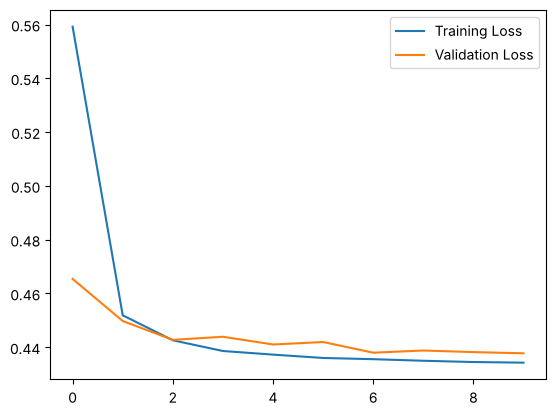

In [15]:
plt.plot(range(len(history.history["loss"])),history.history["loss"],label="Training Loss")
plt.plot(range(len(history.history["val_loss"])),history.history["val_loss"],label="Validation Loss")
plt.legend()

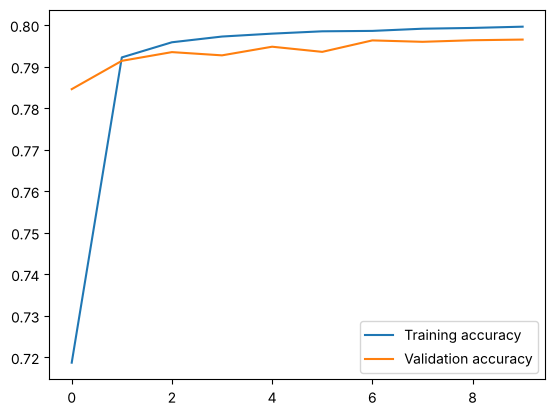

In [16]:
plt.plot(range(len(history.history["accuracy"])),history.history["accuracy"],label="Training accuracy")
plt.plot(range(len(history.history["val_accuracy"])),history.history["val_accuracy"],label="Validation accuracy")
plt.legend()

These two plots are **learning curves**. "I do not believe any training unless I see this plot."
What to look for:

- **Is it improving?** If the loss isn't going down, the model isn't training.
- **Has it plateaued?** Train until the curves flatten out. In this run the validation loss is still
  edging down at epoch 10 (0.4382 → 0.4377), so more epochs might help a little.
- **Do the curves diverge?** If you train a model with enough **capacity** (enough parameters) for
  long enough, the training loss keeps improving while the validation loss starts getting worse. That
  is **over-training** (over-fitting): the model is memorizing the training data. This tiny model has
  little capacity, so its two curves stay together.
- The validation curve wiggles more (see epochs 4, 6 and 8), because it is computed on fewer events.

The instructor's practice: "I purposely over-train, but I save my model along the way and then come
back and pick a model before it over-trained." Keras does this with **callbacks**, code it runs at
set points during training: `ModelCheckpoint` saves the model, and `EarlyStopping` stops training when
the validation loss stops improving (both are shown below). (The x axis here starts at 0 for epoch 1.)

## Callbacks, saving, regularizers

A **callback** is an object `fit` calls at set points: after each batch, after each epoch. "At the end
of each epoch, I want to save my model. Or if I've been training for a long time and my loss function
is not changing, I want to stop." The instructor's stopping rule: "if the loss has not changed by 1% in
10 epochs, then I'm going to stop". In Keras:

```python
from keras.callbacks import EarlyStopping, ModelCheckpoint

callbacks = [EarlyStopping(monitor='val_loss', patience=10, min_delta=0.004, restore_best_weights=True),
             ModelCheckpoint('susy_best.keras', monitor='val_loss', save_best_only=True)]
history = model.fit(X_Train, y_Train, validation_data=(X_Test, y_Test),
                    epochs=200, batch_size=2048, callbacks=callbacks)
```

`min_delta` is an absolute change, so 0.004 is about 1% of a loss near 0.44. **Early stopping** alone
would leave you the *last* model, a few epochs past the best; `restore_best_weights=True` gives back the
best one seen, which is "pick a model before it over-trained". A **model checkpoint** also means a crash
doesn't lose the run: you can load it and continue. **TensorBoard** (a separate package, `tensorboard`)
draws the learning curves live while training runs, through the `TensorBoard` callback.

To keep a model, `model.save('susy_dnn.keras')`; to get it back,
`keras.models.load_model('susy_dnn.keras')`.

The other defence works on the weights themselves. Large weights give a model freedom, "and therefore,
they can overtrain". A **regularizer** adds a penalty for large weights to the loss, layer by layer:
`Dense(12, activation='relu', kernel_regularizer=L2(1e-4))` (with `from keras.regularizers import L2`).
A **constraint** instead limits the weights directly after each step, for example
`kernel_constraint=MaxNorm(3)` (from `keras.constraints`). **Dropout**, which switches off a random
fraction of units at each step, is another regularization.

We can evaluate how the trained model does on the test sample as follows:

In [17]:
scores = model.evaluate(X_Test, y_Test)
print(scores)

1563/1563 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.7965 - loss: 0.4377
[0.4377480745315552, 0.796500027179718]


`evaluate` returns the loss and the metric, `[0.4377, 0.7965]`. These are **exactly** the last
epoch's `val_loss` and `val_accuracy`, because `fit` was given `validation_data=(X_Test, y_Test)`: in
this notebook the validation sample and the test sample are the same 50,000 events.

Here nothing was chosen by looking at those numbers, so no harm is done. But the two samples have
different jobs. The **validation** sample is used while you work: to watch training, choose when to
stop, and compare architectures. The **test** sample is used once, at the end, to report how well
the final model does on data that played no part in any choice. Once you start comparing models, as
in Lab 9, keep a third slice for the test.

While evaluate is useful for assessing performance, once you have trained a model and determined you with to use it, you will want to apply to data without ground truth or the known desired output (in this case signal or background). `predict` enables this functionality:

In [19]:
model(X_Test)

<tf.Tensor: shape=(50000, 1), dtype=float32, numpy=
array([[0.8042343 ],
       [0.10032962],
       [0.1125117 ],
       ...,
       [0.5397238 ],
       [0.34305373],
       [0.1610043 ]], shape=(50000, 1), dtype=float32)>

Each output is the sigmoid's number between 0 and 1. "Because I use a sigmoid, I can loosely interpret
this as the probability of that candidate being signal." Your values will differ from the stored ones:
the weights start random, and no random seed is set (`keras.utils.set_random_seed(42)` at the top
would make runs repeatable).

There are two ways to get outputs. Calling the model, `model(X_Test)`, pushes all 50,000 rows through
at once and returns a TensorFlow tensor (above). `model.predict(X_Test)` works through them in batches
(of 32 by default) and returns a NumPy array, which is what the ROC code below uses. For a big model
or a big dataset, `predict`'s batching is what keeps you from running out of memory.

Note the output here is a number between 0 and 1. Determining what threshold to use to select signal is analgous to what we did for other ML methods.

And we can make ROC curves as before:

1563/1563 ━━━━━━━━━━━━━━━━━━━━ 1s 861us/step


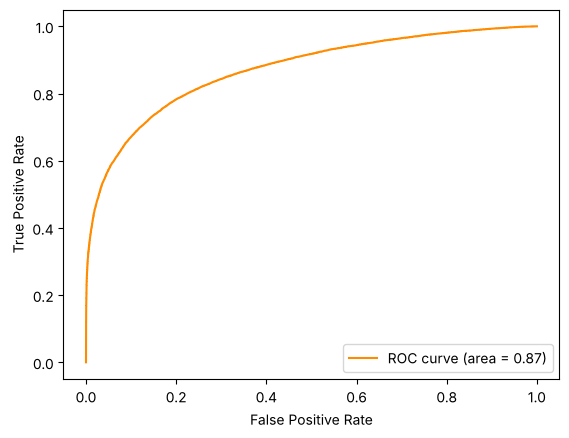

In [20]:
from sklearn.metrics import roc_curve, auc
fpr, tpr, _ = roc_curve(y_Test, model.predict(X_Test))
                        
roc_auc = auc(fpr, tpr)

plt.plot(fpr,tpr,color='darkorange',label='ROC curve (area = %0.2f)' % roc_auc)
plt.legend(loc="lower right")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.show()

This is "a very, very simple template of how to do deep learning": data in, model, compile, fit, check
the learning curves, evaluate, ROC.

**Compare to a baseline.** A complex model has to beat a simple one, or something is wrong. Before
training a deep network, see what a single good feature gives, then a simple method such as
logistic regression or the Fisher discriminant. In the scikit-learn lecture, LDA on the same 18
features reached an AUC of about 0.84. This small network reaches 0.87 (the events differ, so the
comparison is only indicative). The deep network wins, as the original SUSY paper found.

Other people's results are baselines too: the SUSY paper reports its own AUCs for the same features.

It is also worth histogramming the network's output separately for signal and background, as we did
for LDA: the network has replaced 18 features with one, and that plot shows how well it separates them.

```python
p = model.predict(X_Test)[:, 0]
plt.hist(p[y_Test==1], bins=50, alpha=0.5, label='signal')
plt.hist(p[y_Test==0], bins=50, alpha=0.5, label='background')
plt.legend()
```

**Rejection.** In particle physics the backgrounds are enormous, and a selection may have to keep only
1 in 10,000 of them. At such small false-positive rates the ROC curve hugs the axis and can't be read,
so physicists plot the **rejection**, $1/\text{FPR}$, against the **signal efficiency** (the true-positive
rate) on a log scale:

```python
keep = fpr > 0
plt.semilogy(tpr[keep], 1/fpr[keep])
plt.xlabel('Signal efficiency (TPR)')
plt.ylabel('Background rejection (1/FPR)')
```

**Lab 9** asks you to do this yourself: "all you have to do is copy and paste what's in" this lecture
"and modify the numbers". Write a function that takes a `history` and draws its learning curves, since
you will use it for every model, and for each model ask whether it has plateaued; if not, train longer.
Try more units and more layers, and train on the raw features only, the derived features only, and
both. That last comparison repeats the SUSY paper's: by comparing ROC curves its authors concluded that
a deep network learns the derived features from the raw ones by itself. Add your results to Lab 8's
comparison. The point is less the numbers than being ready: "I want you all to be set up. So that if
you get some crazy idea for the summer, you can actually do it and go and try it out quickly."

## Going further: the Keras documentation

"The documentation of Keras is actually rather good... I suggest that you read through it." keras.io
has four parts worth knowing:

- **Developer guides**: one topic each: the functional API (with diagrams of models with several
  inputs, and of skip connections), making new layers and models by subclassing, customizing `fit`,
  writing your own training loop, callbacks, transfer learning.
- **API reference**: every class, organized as this notebook used them: models, layers (core,
  convolutional, pooling, recurrent, text, preprocessing), activations, initializers, regularizers,
  constraints, callbacks, optimizers, losses, metrics, data loading. Read a class's page for its
  arguments and their defaults. A **`Lambda` layer** wraps a plain expression when nobody has written
  the layer you need.
- **Code examples**: "a ridiculous number of examples. Almost anything that you can think of", many
  reproducing a published paper on its own dataset. They show how to make something work, not the best
  possible result. When you are thinking through a problem, look through them, then copy, paste and
  modify, "or at least see how those things are built". "The best thing about Keras beyond everything
  it provides is the examples."
- **Keras Applications**: **pre-trained models**, networks already trained on huge datasets. For
  images, you'd be a fool to train from scratch: take one, "rip off the last layer, put a new layer on",
  and train a little. That is **transfer learning**, later in this chapter.

Things this notebook didn't need but your project might:

- **Preprocessing layers.** Our features went in unscaled: momenta in the tens, cosines between −1 and
  1. A `Normalization` layer learns each feature's mean and spread from the training data and rescales
  inside the model: `norm = Normalization(); norm.adapt(X_Train)`, then `x = norm(in_x)` right after
  the `Input`. Putting preprocessing in the model "allows a model to work as a black box. It ensures
  that the model inputs are always correct": whoever gets your model doesn't also need your
  preprocessing code. The exception is heavy work, such as shrinking large images, which is better done
  once, up front.
- **Data loaders.** When data doesn't fit in memory, a loader reads and prepares the next batches on
  the CPU while the GPU computes. `keras.utils.image_dataset_from_directory` reads one sub-folder per
  class, batches and resizes the images, and can **augment** them (make altered copies, flipped or
  rotated, to enlarge the training set).
- **Mixed precision.** Computing some things with 16-bit instead of 32-bit numbers saves GPU memory,
  often without losing performance.
- **Several GPUs.** Splitting each batch across devices changes how the loss is computed, and Keras has
  utilities for it. Parallel computing comes later in the course.

"You don't have to use Keras. You can use PyTorch directly. I have used both." Keras's case is that it
is a good abstraction layer: you describe the model once, and switching the backend takes few changes.